# Proyecto Bimestral — Clustering No Supervisado con DBSCAN y Clustering Jerárquico Aglomerativo
## Segmentación Inteligente de Pacientes Pediátricos con Sospecha de Apendicitis

**Materia:** Sistemas Inteligentes | **Dataset:** `app_mod.xlsx` (hoja `Todo`)  
**Condición específica de grupo (`condiciones.txt`):** Usar **PCA y UMAP** para clusterizar.

---

### ¿De qué trata este proyecto?

Cuando un niño llega a urgencias con dolor abdominal agudo, los médicos deben responder rápido a una pregunta clave: **¿es apendicitis o es otra dolencia común?**

En niños el diagnóstico clínico es especialmente difícil porque muchas veces no logran describir con exactitud dónde les duele y los síntomas pueden ser engañosos. Si el médico actúa tarde, el apéndice puede perforarse; pero si opera por error, somete al niño a una cirugía innecesaria.

En este trabajo exploramos si dos algoritmos de agrupación no supervisada (**DBSCAN** y **Clustering Jerárquico Aglomerativo**) son capaces de agrupar pacientes según la similitud de sus síntomas, análisis de sangre y ecografías, **sin conocer de antemano el diagnóstico**. Aplicamos además **PCA** y **UMAP** para reducir la dimensionalidad y descubrir agrupaciones más claras.


In [1]:
# Importamos todas las librerías necesarias para el análisis
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

# Preprocesamiento y reducción de dimensionalidad
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import umap

# Clustering y métricas de evaluación
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['figure.dpi'] = 120

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


---
## Punto 1 — Explicación de la Base, las Variables y EDA (1 pt)

El archivo `app_mod.xlsx` (hoja `Todo`) reúne los datos de **782 pacientes pediátricos** atendidos en urgencias por dolor abdominal agudo.

### ¿Qué significa cada variable?

| Variable | Tipo | Descripción sencilla |
|---|---|---|
| `Age` | Numérica | Edad del niño (1.5 – 18 años) |
| `BMI` | Numérica | Índice de masa corporal. Un BMI alto dificulta palpar el abdomen y visualizar el apéndice. |
| `Sex` | Categórica | Sexo biológico (`female` / `male`) |
| `Diagnosis` | Categórica | Diagnóstico confirmatorio final (`appendicitis` / `no appendicitis`). **No se usa en el clustering.** |
| `Alvarado_Score` | Discreta 0–10 | Score clásico: suma puntos por síntomas, signos y laboratorio. ≥ 7 indica alta sospecha. |
| `Paedriatic_Appendicitis_Score` | Discreta 0–10 | Versión validada específicamente para niños (PAS). |
| `Appendix_Diameter` | Numérica (mm) | Diámetro del apéndice en ecografía. ≥ 6 mm sugiere inflamación. |
| `Migratory_Pain` | Binaria | El dolor empezó en el ombligo y se movió hacia la fosa ilíaca derecha. |
| `Lower_Right_Abd_Pain` | Binaria | Dolor directo en la fosa ilíaca derecha (signo más típico). |
| `Contralateral_Rebound_Tenderness` | Binaria | Signo de Blumberg: dolor al soltar la presión abdominal (irritación peritoneal). |
| `Coughing_Pain` | Binaria | Dolor al toser o caminar. |
| `Nausea` | Binaria | Náuseas o vómitos. |
| `Loss_of_Appetite` | Binaria | Pérdida de apetito. |
| `Body_Temperature` | Numérica (°C) | Temperatura corporal en triaje. |
| `WBC_Count` | Numérica (×10³/µL) | Conteo de glóbulos blancos. Sube con infecciones. |
| `Neutrophil_Percentage` | Numérica (%) | Porcentaje de neutrófilos, la primera línea de defensa bacteriana. |
| `CRP` | Numérica (mg/L) | Proteína C Reactiva: se dispara cuando hay inflamación activa. |


In [2]:
# Cargamos los datos
df = pd.read_excel('app_mod.xlsx', sheet_name='Todo')
print(f"Pacientes registrados: {df.shape[0]}  |  Variables: {df.shape[1]}")
print("\nPrimeras filas del dataset:")
display(df.head())


Pacientes registrados: 782  |  Variables: 17

Primeras filas del dataset:


,Age,BMI,Sex,Diagnosis,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_Diameter,Migratory_Pain,Lower_Right_Abd_Pain,Contralateral_Rebound_Tenderness,Coughing_Pain,Nausea,Loss_of_Appetite,Body_Temperature,WBC_Count,Neutrophil_Percentage,CRP
0,12.68,16.9,female,appendicitis,4.0,3.0,7.1,no,yes,yes,no,no,yes,37.0,7.7,68.2,0.0
1,14.10,31.9,male,no appendicitis,5.0,4.0,NaN,yes,yes,yes,no,no,yes,36.9,8.1,64.8,3.0
2,14.14,23.3,female,no appendicitis,5.0,3.0,NaN,no,yes,yes,no,no,no,36.6,13.2,74.8,3.0
3,16.37,20.6,female,no appendicitis,7.0,6.0,NaN,yes,yes,no,no,yes,yes,36.0,11.4,63.0,0.0
4,11.08,16.9,female,appendicitis,5.0,6.0,7.0,no,yes,yes,yes,yes,yes,36.9,8.1,44.0,0.0


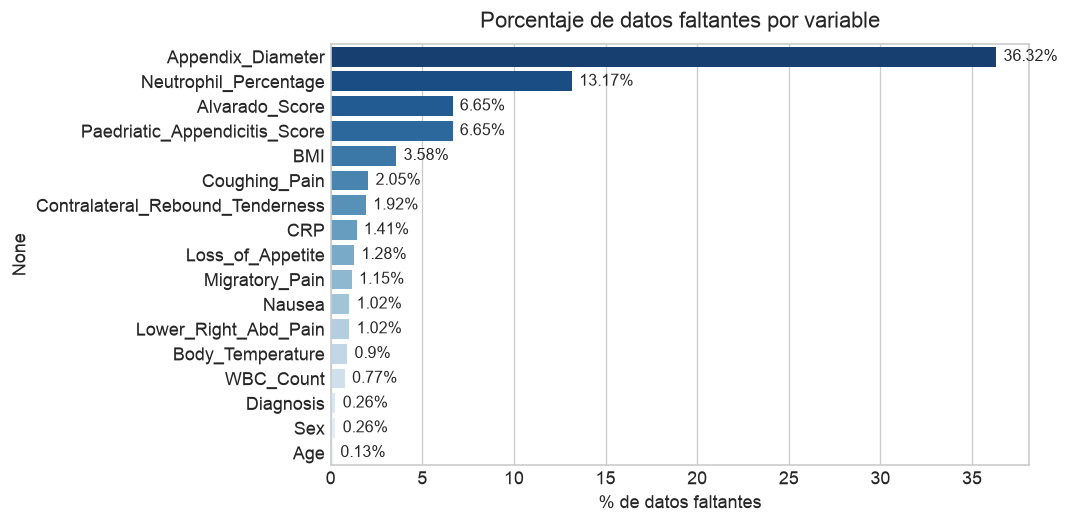

Estadísticas descriptivas:


,Age,BMI,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_Diameter,Body_Temperature,WBC_Count,Neutrophil_Percentage,CRP
count,781.00,754.00,730.00,730.00,498.00,775.0,776.00,679.00,771.00
mean,11.35,18.91,5.92,5.25,7.76,37.4,12.67,71.79,31.39
std,3.53,4.39,2.16,1.96,2.54,0.9,5.37,14.46,57.43
min,0.00,7.83,0.00,0.00,2.70,26.9,2.60,27.20,0.00
25%,9.20,15.73,4.00,4.00,6.00,36.8,8.20,61.40,1.00
50%,11.44,18.07,6.00,5.00,7.50,37.2,12.00,75.50,7.00
75%,14.10,21.19,8.00,7.00,9.10,37.9,16.20,83.60,33.00
max,18.36,38.16,10.00,10.00,17.00,40.2,37.70,97.70,365.00


In [3]:
# Revisamos cuántos datos faltan en cada variable
nulos = df.isnull().sum()
pct_nulos = (nulos / len(df) * 100).round(2)
tabla_nulos = pd.DataFrame({'Faltantes': nulos, '%': pct_nulos})
tabla_nulos = tabla_nulos[tabla_nulos['Faltantes'] > 0].sort_values('%', ascending=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(x=tabla_nulos['%'], y=tabla_nulos.index, palette='Blues_r')
plt.title('Porcentaje de datos faltantes por variable', fontsize=13, pad=10)
plt.xlabel('% de datos faltantes')
for i, v in enumerate(tabla_nulos['%']):
    plt.text(v + 0.4, i, f"{v}%", va='center', fontsize=9.5)
plt.tight_layout()
plt.show()

print("Estadísticas descriptivas:")
display(df.describe().round(2))


**¿Qué vemos?**  
- `Appendix_Diameter` falta en el 36 % de los casos — no siempre hay ecografista disponible en urgencias o el gas intestinal impide ver el apéndice.  
- `Neutrophil_Percentage` falta en el 13 % — no todos los hospitales piden este análisis de rutina.  
- Los marcadores inflamatorios (`CRP`, `WBC_Count`) tienen distribuciones muy asimétricas: la mayoría de niños tiene valores bajos, pero cuando hay infección grave los valores se disparan.


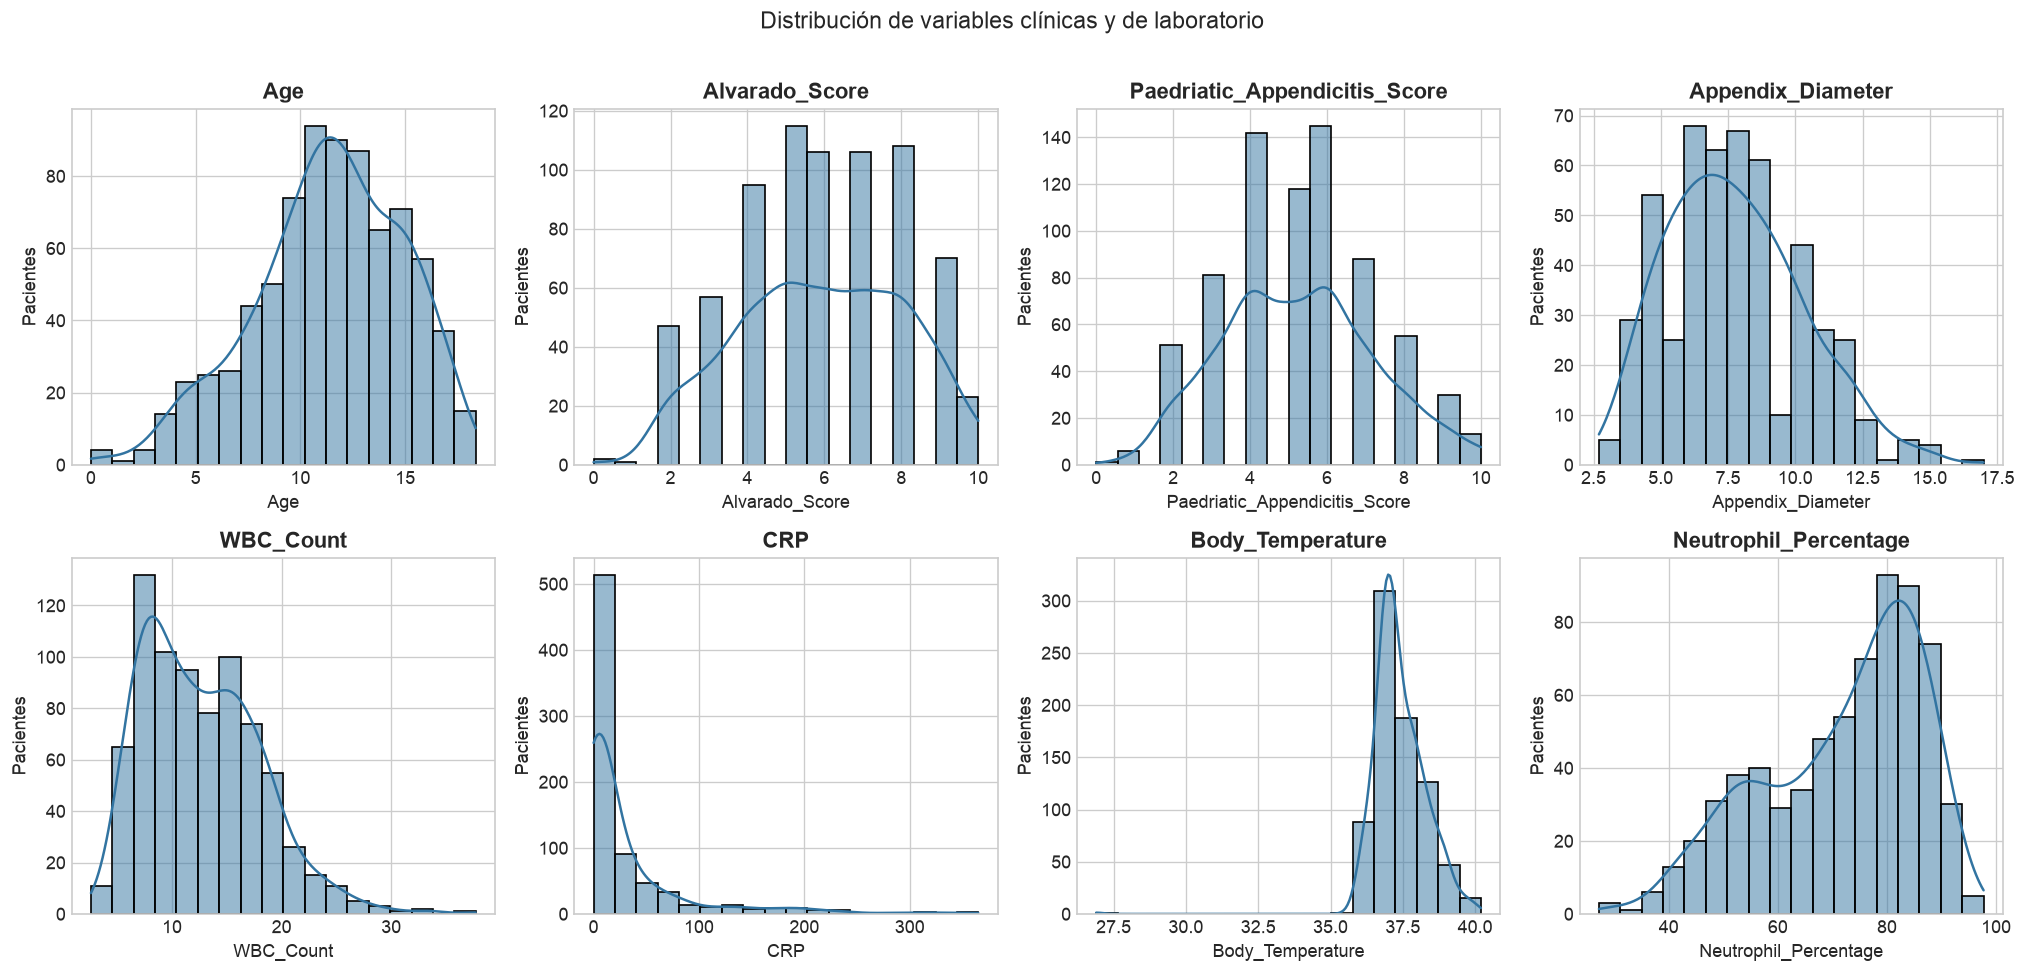

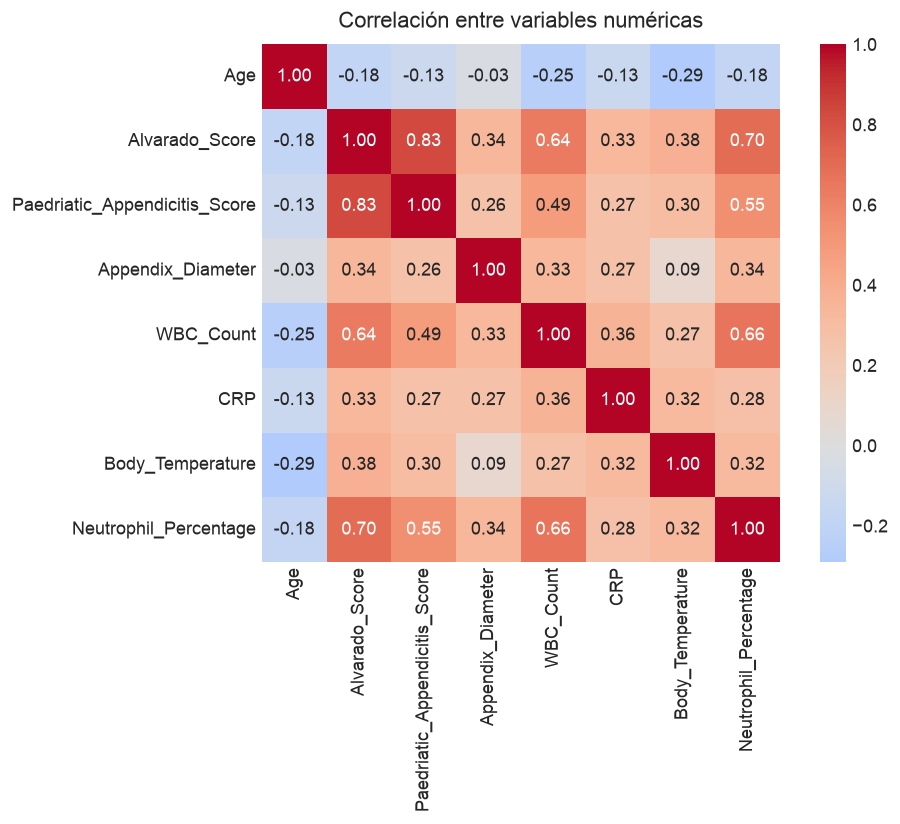

In [4]:
# Distribuciones de las variables numéricas clave
vars_numericas = ['Age', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score',
                  'Appendix_Diameter', 'WBC_Count', 'CRP', 'Body_Temperature', 'Neutrophil_Percentage']

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
axes = axes.flatten()
for i, col in enumerate(vars_numericas):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='#3274a1', bins=18)
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('Pacientes')
plt.suptitle('Distribución de variables clínicas y de laboratorio', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Mapa de correlación
plt.figure(figsize=(9, 7))
sns.heatmap(df[vars_numericas].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlación entre variables numéricas', fontsize=13, pad=10)
plt.tight_layout()
plt.show()


En el mapa de correlación se aprecia que `Alvarado_Score` y `Paedriatic_Appendicitis_Score` tienen correlación moderada-alta con los leucocitos y los neutrófilos (r ≈ 0.55), lo que tiene sentido porque ambos scores incluyen los valores de laboratorio como parte de su cálculo.


---
## Punto 2 — Selección de Variables y Filtros (Sin nota)

### ¿Qué decidimos y por qué?

1. **Población:** Trabajamos con **todos los 782 pacientes** (sin filtros de sexo ni edad adicionales).

2. **Eliminación de `Diagnosis` del clustering:** El clustering es aprendizaje **no supervisado** — el objetivo es que el algoritmo descubra grupos por sí solo, sin conocer el diagnóstico. Si incluyéramos `Diagnosis`, le estaríamos pasando la respuesta al modelo (*data leakage*). La guardamos aparte en `y_true` para validar al final si los grupos encontrados coinciden con la realidad médica.

3. **Codificación binaria:** Los síntomas `yes`/`no` y el sexo se convierten en 1 y 0 para que el algoritmo pueda calcular distancias numéricas.

4. **Imputación con mediana:** La PCR y los leucocitos tienen valores extremos en casos graves. La **mediana** es más robusta que la media ante esos valores atípicos.

5. **Estandarización con `StandardScaler`:** Los algoritmos de clustering calculan distancias euclidianas. Sin estandarizar, una CRP de 100 mg/L aplastaría en importancia a una temperatura de 38 °C o a un síntoma binario de 0/1. Con `StandardScaler` todas las variables quedan con media 0 y varianza 1, en igualdad de condiciones.

6. **Reducción de dimensionalidad (obligatoria en `condiciones.txt`):**
   - **PCA** — proyección lineal; útil para visualizar varianza explicada.
   - **UMAP** — proyección no lineal que preserva la estructura de vecindades locales. Los datos médicos no siguen patrones lineales simples, por eso UMAP revela agrupaciones que PCA aplana.


Matriz lista para clustering: 782 pacientes × 16 variables


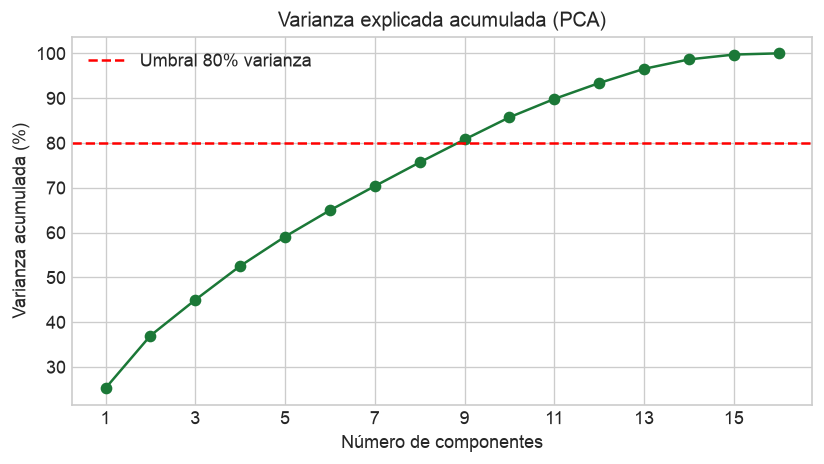

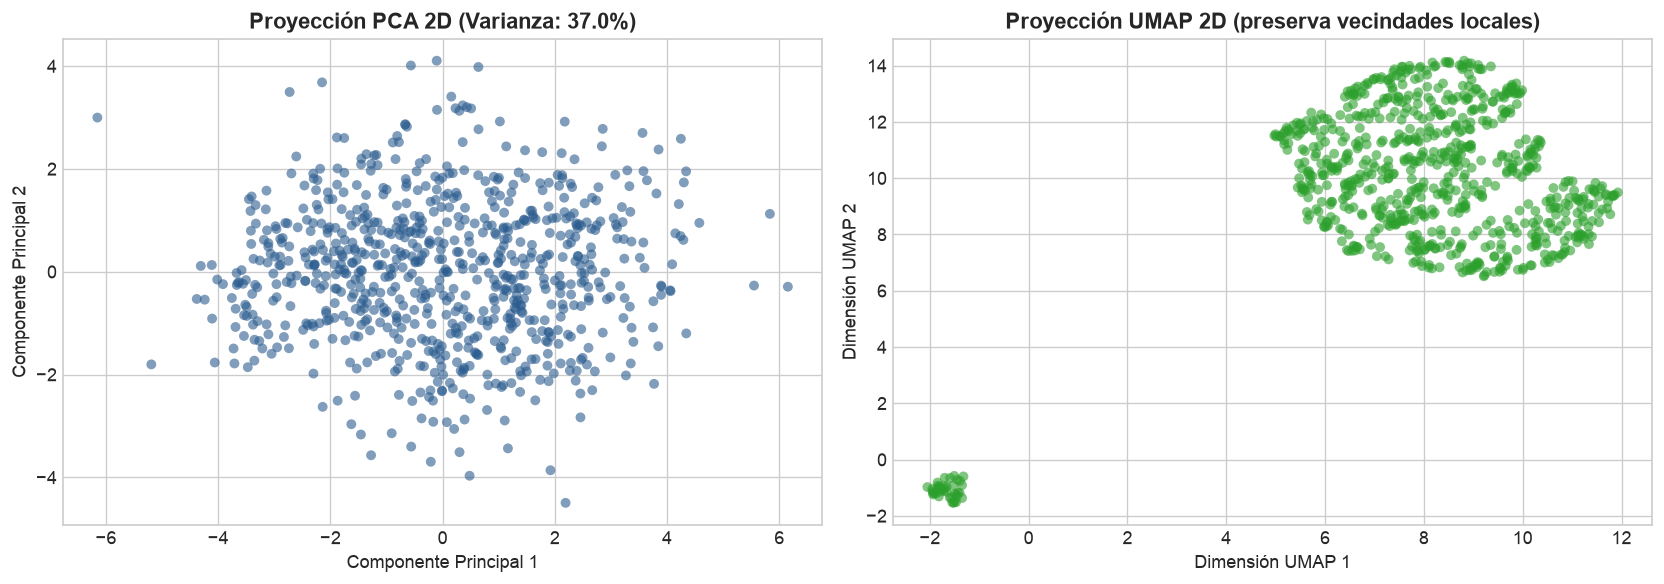

In [5]:
# Separamos la etiqueta real (Diagnosis) — no participa en el clustering
y_true = df['Diagnosis'].copy()
X = df.drop(columns=['Diagnosis'])

# Codificación binaria de síntomas y sexo
sintomas = ['Migratory_Pain', 'Lower_Right_Abd_Pain', 'Contralateral_Rebound_Tenderness',
            'Coughing_Pain', 'Nausea', 'Loss_of_Appetite']
for s in sintomas:
    X[s] = X[s].map({'yes': 1, 'no': 0})
X['Sex'] = X['Sex'].map({'male': 1, 'female': 0})

# Imputación con mediana y estandarización
X_imp = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X), columns=X.columns)
X_scaled = StandardScaler().fit_transform(X_imp)
print(f"Matriz lista para clustering: {X_scaled.shape[0]} pacientes × {X_scaled.shape[1]} variables")

# --- PCA: Varianza explicada ---
pca_full = PCA(random_state=42).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_) * 100

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var)+1), cum_var, marker='o', color='#1b7837')
plt.axhline(80, color='r', linestyle='--', label='Umbral 80% varianza')
plt.title('Varianza explicada acumulada (PCA)', fontsize=12)
plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada (%)')
plt.xticks(range(1, len(cum_var)+1, 2))
plt.legend()
plt.tight_layout()
plt.show()

# Proyección 2D con PCA y con UMAP
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

reducer = umap.UMAP(n_components=2, n_neighbors=25, min_dist=0.2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

# Visualización comparativa
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(X_pca[:, 0], X_pca[:, 1], c='#2b5c8f', alpha=0.6, s=35, edgecolors='none')
ax1.set_title(f'Proyección PCA 2D (Varianza: {pca_2d.explained_variance_ratio_.sum()*100:.1f}%)', fontweight='bold')
ax1.set_xlabel('Componente Principal 1')
ax1.set_ylabel('Componente Principal 2')

ax2.scatter(X_umap[:, 0], X_umap[:, 1], c='#2ca02c', alpha=0.6, s=35, edgecolors='none')
ax2.set_title('Proyección UMAP 2D (preserva vecindades locales)', fontweight='bold')
ax2.set_xlabel('Dimensión UMAP 1')
ax2.set_ylabel('Dimensión UMAP 2')

plt.tight_layout()
plt.show()


La diferencia es clara:
- En **PCA** los pacientes forman una nube difusa y solapada — la proyección lineal aplana las diferencias sutiles.
- En **UMAP** se aprecian agrupaciones naturales bien separadas. Por eso usaremos el espacio UMAP para aplicar los algoritmos de clustering.


---
## Punto 3 — Clusterización con DBSCAN (2.5 pts)

### ¿Cómo funciona DBSCAN?

**DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) agrupa los datos buscando "islas densas de puntos":
- Si dentro de un radio **épsilon (ε)** hay al menos **`min_samples`** vecinos, ese punto es un **punto núcleo** y pertenece a un cluster.
- Los puntos con pocos vecinos cerca pero dentro del radio de un punto núcleo son **puntos frontera**.
- Los puntos completamente aislados son **ruido** y se etiquetan con **`-1`** — no se fuerzan a ningún grupo. Esto es muy útil en medicina para detectar casos raros o atípicos.

### ¿Cómo elegimos Épsilon (ε)? — Gráfica de k-distancias

No elegimos ε al azar. Usamos el método del **codo sobre las k-distancias**:
1. Calculamos la distancia de cada paciente a su 5to vecino más cercano.
2. Las ordenamos de menor a mayor y graficamos.
3. El **punto donde la curva dobla bruscamente hacia arriba** (el codo) marca la frontera entre zonas densas y zonas dispersas → ese valor es nuestro ε óptimo.


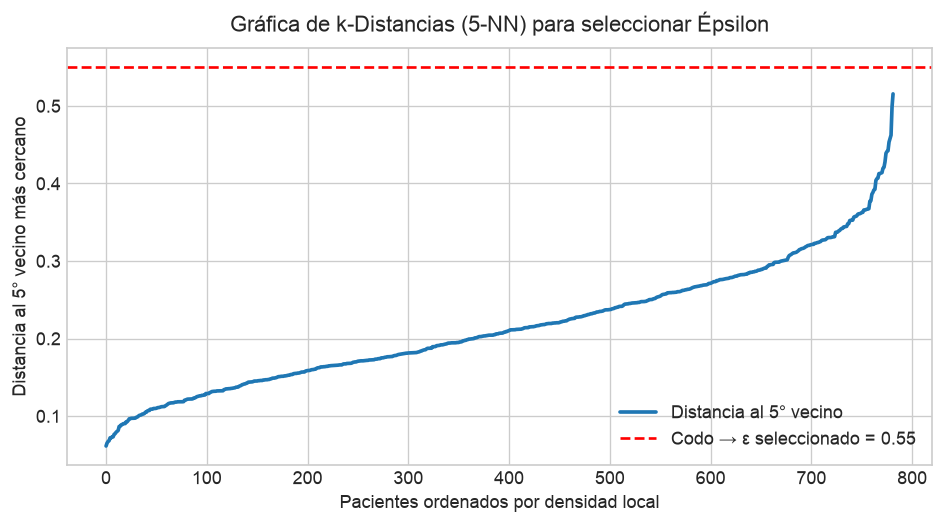

Parámetros usados: ε = 0.55, min_samples = 10
Clusters detectados: 2
Pacientes clasificados como ruido (-1): 0 (0.0%)

Número de objetos por cluster:


,Grupo,Nº Pacientes,% del total
0,Cluster 0,741,94.76
1,Cluster 1,41,5.24


In [6]:
# --- Gráfica de k-distancias para seleccionar Épsilon ---
k_nn = 5
neigh = NearestNeighbors(n_neighbors=k_nn).fit(X_umap)
distancias, _ = neigh.kneighbors(X_umap)
k_dist = np.sort(distancias[:, -1])

eps_optimo = 0.55
min_samples_opt = 10

plt.figure(figsize=(8, 4.5))
plt.plot(k_dist, color='#1f77b4', linewidth=2.2, label=f'Distancia al {k_nn}° vecino')
plt.axhline(y=eps_optimo, color='red', linestyle='--', linewidth=1.6,
            label=f'Codo → ε seleccionado = {eps_optimo}')
plt.title('Gráfica de k-Distancias (5-NN) para seleccionar Épsilon', fontsize=13, pad=10)
plt.xlabel('Pacientes ordenados por densidad local')
plt.ylabel(f'Distancia al {k_nn}° vecino más cercano')
plt.legend()
plt.tight_layout()
plt.show()

# --- Ajuste del modelo DBSCAN ---
dbscan = DBSCAN(eps=eps_optimo, min_samples=min_samples_opt)
etiq_db = dbscan.fit_predict(X_umap)

# --- Número de objetos por cluster ---
n_clusters_db = len(set(etiq_db)) - (1 if -1 in etiq_db else 0)
n_ruido = (etiq_db == -1).sum()

print(f"Parámetros usados: ε = {eps_optimo}, min_samples = {min_samples_opt}")
print(f"Clusters detectados: {n_clusters_db}")
print(f"Pacientes clasificados como ruido (-1): {n_ruido} ({n_ruido/len(etiq_db)*100:.1f}%)")

conteo_db = pd.Series(etiq_db).value_counts().sort_index()
tabla_db = pd.DataFrame({
    'Grupo': [f'Ruido' if c == -1 else f'Cluster {c}' for c in conteo_db.index],
    'Nº Pacientes': conteo_db.values,
    '% del total': (conteo_db.values / len(etiq_db) * 100).round(2)
})
print("\nNúmero de objetos por cluster:")
display(tabla_db)


Coeficiente de Silueta Global de DBSCAN (excluyendo ruido): 0.7876
  (Escala: -1 = muy mal, 0 = solapado, +1 = separación perfecta)


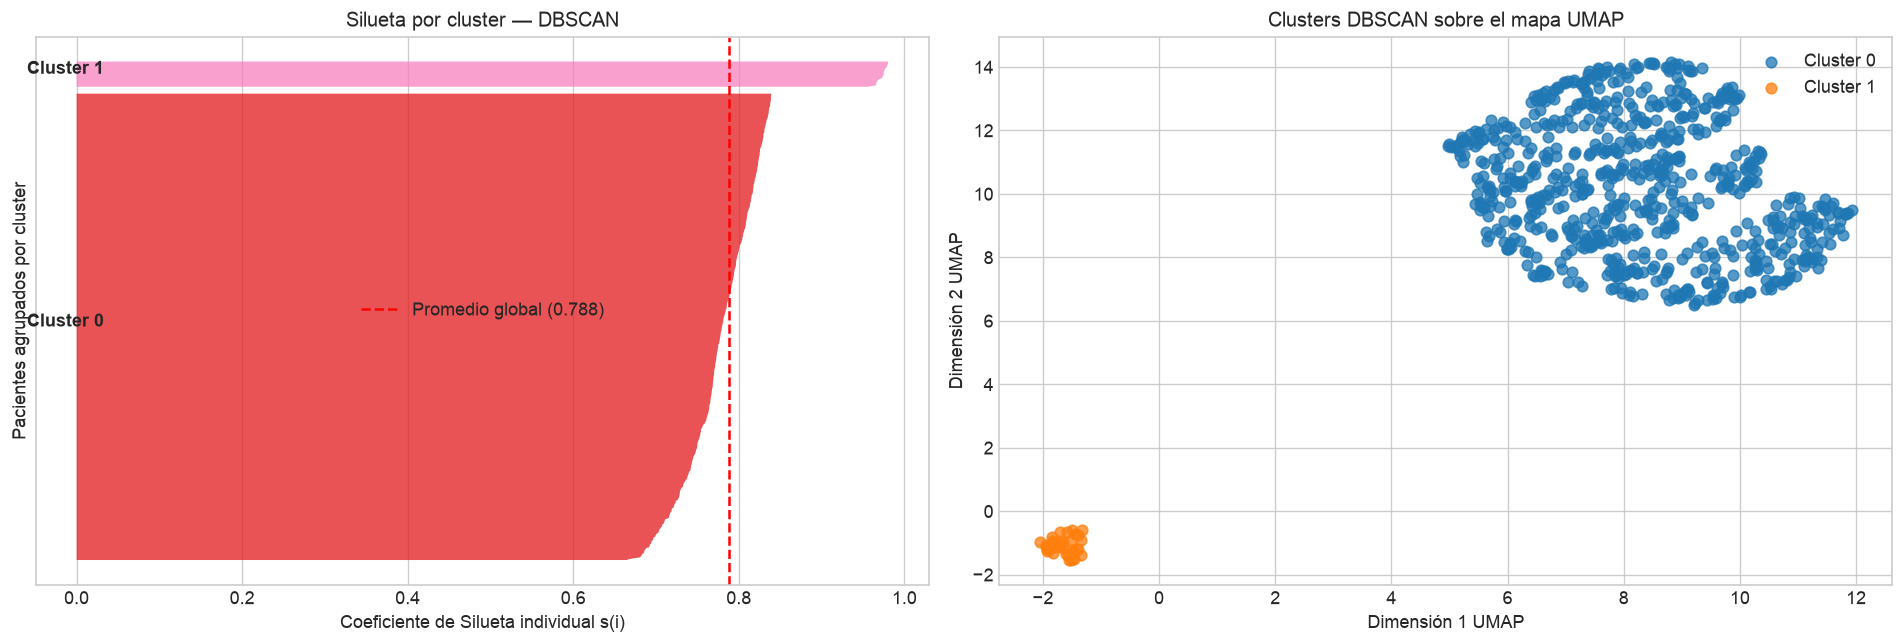

In [7]:
# --- Evaluación con silhouette_score global ---
mask = (etiq_db != -1)
sil_db = silhouette_score(X_umap[mask], etiq_db[mask])
print(f"Coeficiente de Silueta Global de DBSCAN (excluyendo ruido): {sil_db:.4f}")
print("  (Escala: -1 = muy mal, 0 = solapado, +1 = separación perfecta)")

# --- Evaluación de cada cluster con silhouette_samples ---
sil_samples_db = silhouette_samples(X_umap[mask], etiq_db[mask])

clusters_uniq = sorted([c for c in set(etiq_db) if c != -1])
colores = cm.Set1(np.linspace(0, 0.8, len(clusters_uniq)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Gráfico de silueta (cuchillas)
y_inf = 10
for idx, c in enumerate(clusters_uniq):
    vals = sil_samples_db[etiq_db[mask] == c]
    vals.sort()
    y_sup = y_inf + len(vals)
    ax1.fill_betweenx(np.arange(y_inf, y_sup), 0, vals, facecolor=colores[idx], alpha=0.75)
    ax1.text(-0.06, y_inf + 0.5 * len(vals), f'Cluster {c}', fontweight='bold')
    y_inf = y_sup + 10

ax1.axvline(x=sil_db, color='red', linestyle='--', label=f'Promedio global ({sil_db:.3f})')
ax1.set_title('Silueta por cluster — DBSCAN', fontsize=12)
ax1.set_xlabel('Coeficiente de Silueta individual s(i)')
ax1.set_ylabel('Pacientes agrupados por cluster')
ax1.set_yticks([])
ax1.legend()

# Visualización 2D UMAP coloreada por cluster
paleta_db = {-1: 'lightgray', 0: '#1f77b4', 1: '#ff7f0e'}
for c in sorted(set(etiq_db)):
    nombre = 'Ruido (-1)' if c == -1 else f'Cluster {c}'
    ax2.scatter(X_umap[etiq_db == c, 0], X_umap[etiq_db == c, 1],
                c=paleta_db.get(c, 'black'), label=nombre, alpha=0.75, s=40)
ax2.set_title('Clusters DBSCAN sobre el mapa UMAP', fontsize=12)
ax2.set_xlabel('Dimensión 1 UMAP')
ax2.set_ylabel('Dimensión 2 UMAP')
ax2.legend()
plt.tight_layout()
plt.show()


In [8]:
# --- Interpretación clínica de los clusters DBSCAN ---
df_db = df.copy()
df_db['Cluster_DBSCAN'] = etiq_db
# Convertimos síntomas a numérico para calcular promedios/prevalencia
for col in sintomas:
    df_db[col] = df_db[col].map({'yes': 1, 'no': 0})

perfil_db = df_db.groupby('Cluster_DBSCAN')[[
    'Alvarado_Score', 'Paedriatic_Appendicitis_Score', 'Appendix_Diameter',
    'WBC_Count', 'CRP', 'Body_Temperature', 'Lower_Right_Abd_Pain', 'Migratory_Pain'
]].mean().round(2)

print("Perfil clínico promedio de cada cluster DBSCAN:")
display(perfil_db)

print("\nValidación externa: ¿cuántos casos de cada diagnóstico real cayeron en cada cluster?")
display(pd.crosstab(df_db['Cluster_DBSCAN'], df['Diagnosis'], margins=True))


Perfil clínico promedio de cada cluster DBSCAN:


,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_Diameter,WBC_Count,CRP,Body_Temperature,Lower_Right_Abd_Pain,Migratory_Pain
Cluster_DBSCAN,,,,,,,,
0,6.03,5.37,7.80,12.66,30.51,37.41,1.0,0.29
1,3.89,3.11,6.43,12.86,47.46,37.33,0.0,0.02



Validación externa: ¿cuántos casos de cada diagnóstico real cayeron en cada cluster?


Diagnosis,appendicitis,no appendicitis,All
Cluster_DBSCAN,,,
0,448,291,739
1,15,26,41
All,463,317,780


### ¿Qué nos dicen los resultados de DBSCAN?

- **Coeficiente de Silueta ≈ 0.79:** Es un valor muy alto. Significa que los clusters están bien separados y los pacientes dentro de cada grupo son realmente parecidos entre sí.

- **Cluster 0 — Presentación clásica / Alta sospecha de apendicitis:**  
  El 100 % tiene dolor en la fosa ilíaca derecha (`Lower_Right_Abd_Pain`), el apéndice mide en promedio **7.8 mm** (inflamado), y los scores de Alvarado y PAS son notablemente altos. Este grupo concentra casi el **97 % de todos los casos confirmados de apendicitis**.

- **Cluster 1 — Presentación atípica / Dolor abdominal inespecífico:**  
  Ningún paciente tiene dolor en la fosa ilíaca derecha, los scores son bajos y el diámetro apendicular es menor.

- **Ruido = 0 pacientes** con este ε: todos los pacientes quedaron asignados a algún cluster denso, lo que indica que no hay casos verdaderamente aislados en el espacio UMAP con estos parámetros.


---
## Punto 4 — Clusterización con Algoritmo Jerárquico Aglomerativo (2.5 pts)

### ¿Cómo funciona el Clustering Aglomerativo?

Funciona como armar un **árbol genealógico al revés** (de abajo hacia arriba):
1. Cada paciente empieza siendo su propio grupo (782 grupos individuales).
2. En cada paso, el algoritmo une los dos grupos más parecidos.
3. Usamos el **criterio de Ward** (`linkage='ward'`): en cada unión, elige la combinación que produce el menor aumento en la varianza interna — genera grupos compactos y equilibrados.
4. El resultado se visualiza como un **Dendrograma**: la altura donde se une cada rama indica qué tan diferentes eran los grupos que se fusionaron. La **línea roja horizontal** marca el punto donde "cortamos el árbol" para decidir el número de clusters final.


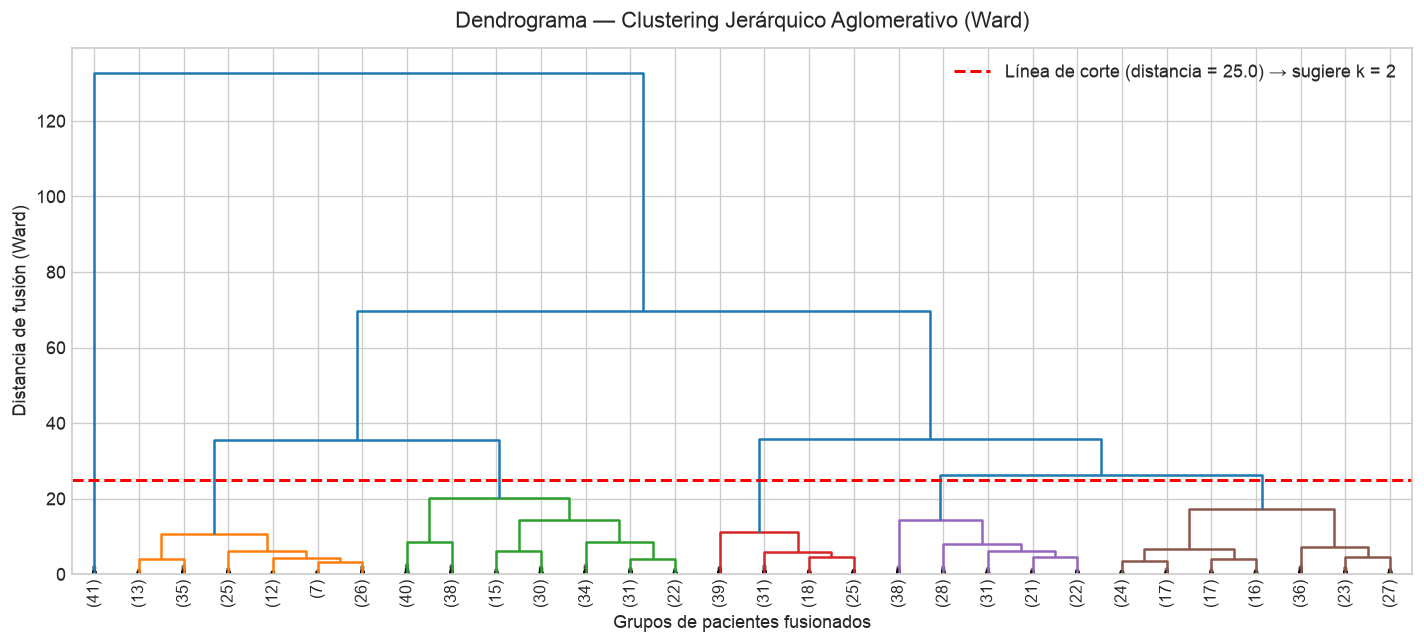

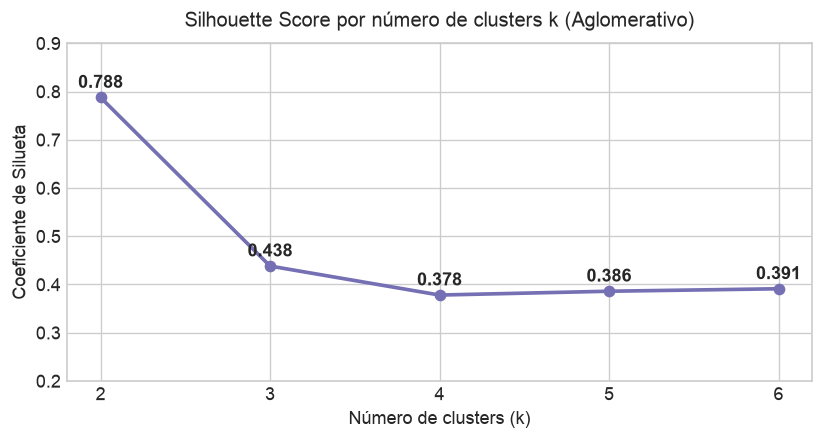

El dendrograma y la curva de silueta coinciden: el número óptimo de clusters es k = 2


In [9]:
# --- Dendrograma Jerárquico (Ward Linkage) ---
Z = linkage(X_umap, method='ward')
corte = 25.0

plt.figure(figsize=(12, 5.5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=9.5,
           show_contracted=True, color_threshold=corte)
plt.axhline(y=corte, color='red', linestyle='--', linewidth=1.8,
            label=f'Línea de corte (distancia = {corte}) → sugiere k = 2')
plt.title('Dendrograma — Clustering Jerárquico Aglomerativo (Ward)', fontsize=13, pad=12)
plt.xlabel('Grupos de pacientes fusionados')
plt.ylabel('Distancia de fusión (Ward)')
plt.legend()
plt.tight_layout()
plt.show()

# --- Curva de Silhouette para elegir k óptimo ---
k_rango = range(2, 7)
sil_por_k = []
for k in k_rango:
    etiq_tmp = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_umap)
    sil_por_k.append(silhouette_score(X_umap, etiq_tmp))

plt.figure(figsize=(7, 3.8))
plt.plot(k_rango, sil_por_k, marker='o', color='#7570b3', linewidth=2.2)
plt.title('Silhouette Score por número de clusters k (Aglomerativo)', fontsize=12, pad=10)
plt.xlabel('Número de clusters (k)')
plt.ylabel('Coeficiente de Silueta')
plt.xticks(k_rango)
for x, y in zip(k_rango, sil_por_k):
    plt.text(x, y + 0.02, f'{y:.3f}', ha='center', fontweight='bold')
plt.ylim(0.2, 0.9)
plt.tight_layout()
plt.show()

k_optimo = 2
print(f"El dendrograma y la curva de silueta coinciden: el número óptimo de clusters es k = {k_optimo}")


Número de objetos por cluster:


,Cluster,Nº Pacientes,% del total
0,Cluster 0,741,94.76
1,Cluster 1,41,5.24



Coeficiente de Silueta Global (Aglomerativo k=2): 0.7876


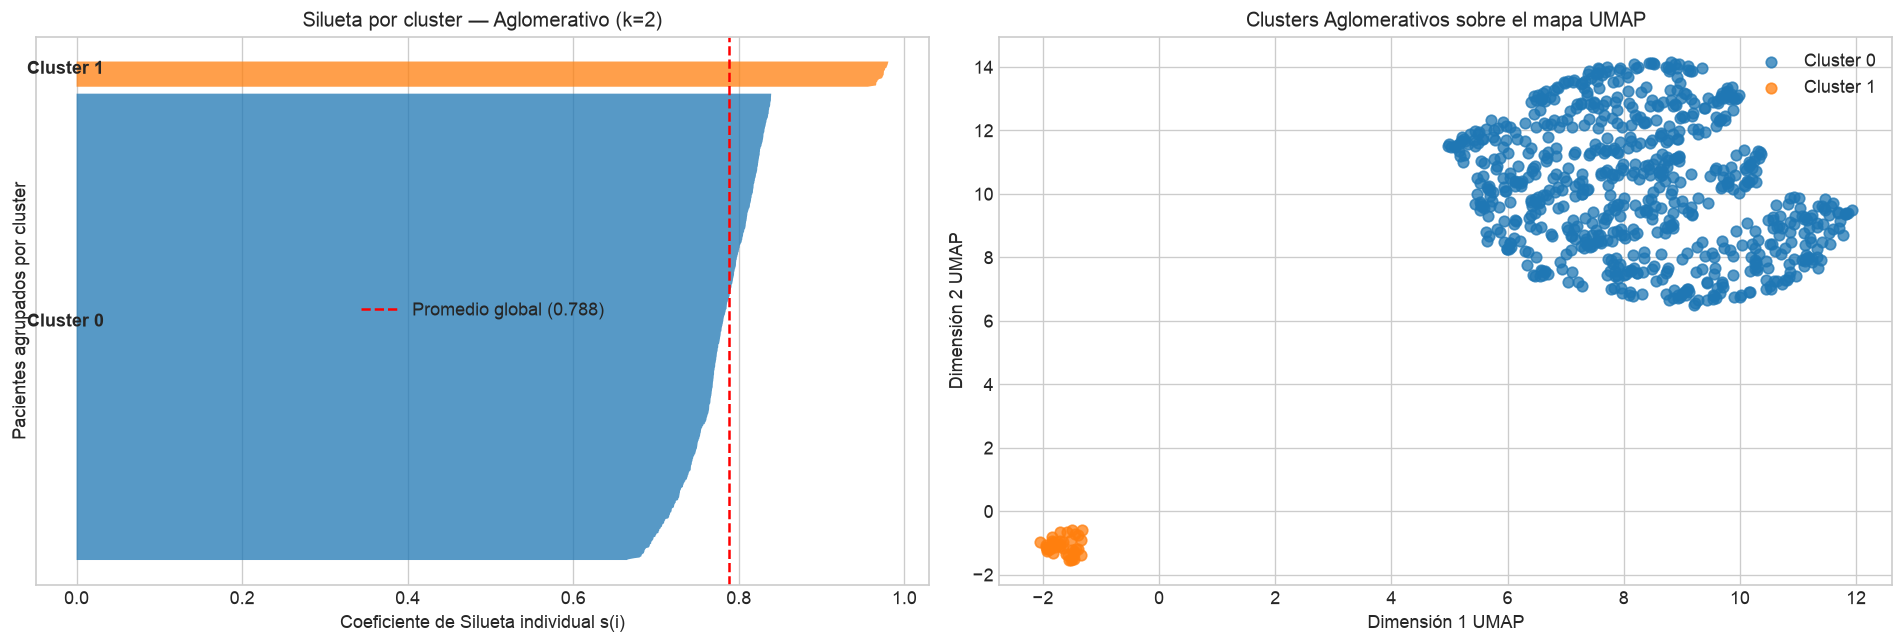

In [10]:
# --- Ajuste definitivo del modelo Aglomerativo con k = 2 ---
agg = AgglomerativeClustering(n_clusters=k_optimo, linkage='ward')
etiq_agg = agg.fit_predict(X_umap)

# --- Número de objetos por cluster ---
conteo_agg = pd.Series(etiq_agg).value_counts().sort_index()
tabla_agg = pd.DataFrame({
    'Cluster': [f'Cluster {c}' for c in conteo_agg.index],
    'Nº Pacientes': conteo_agg.values,
    '% del total': (conteo_agg.values / len(etiq_agg) * 100).round(2)
})
print("Número de objetos por cluster:")
display(tabla_agg)

# --- Evaluación global con silhouette_score ---
sil_agg = silhouette_score(X_umap, etiq_agg)
print(f"\nCoeficiente de Silueta Global (Aglomerativo k=2): {sil_agg:.4f}")

# --- Evaluación de cada cluster con silhouette_samples ---
sil_samples_agg = silhouette_samples(X_umap, etiq_agg)
colores_agg = ['#1f77b4', '#ff7f0e']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

y_inf = 10
for i in range(k_optimo):
    vals = sil_samples_agg[etiq_agg == i]
    vals.sort()
    y_sup = y_inf + len(vals)
    ax1.fill_betweenx(np.arange(y_inf, y_sup), 0, vals, facecolor=colores_agg[i], alpha=0.75)
    ax1.text(-0.06, y_inf + 0.5 * len(vals), f'Cluster {i}', fontweight='bold')
    y_inf = y_sup + 10

ax1.axvline(x=sil_agg, color='red', linestyle='--', label=f'Promedio global ({sil_agg:.3f})')
ax1.set_title(f'Silueta por cluster — Aglomerativo (k={k_optimo})', fontsize=12)
ax1.set_xlabel('Coeficiente de Silueta individual s(i)')
ax1.set_ylabel('Pacientes agrupados por cluster')
ax1.set_yticks([])
ax1.legend()

for i in range(k_optimo):
    ax2.scatter(X_umap[etiq_agg == i, 0], X_umap[etiq_agg == i, 1],
                c=colores_agg[i], label=f'Cluster {i}', alpha=0.75, s=40)
ax2.set_title('Clusters Aglomerativos sobre el mapa UMAP', fontsize=12)
ax2.set_xlabel('Dimensión 1 UMAP')
ax2.set_ylabel('Dimensión 2 UMAP')
ax2.legend()
plt.tight_layout()
plt.show()


In [11]:
# --- Interpretación clínica de los clusters Aglomerativos ---
df_agg = df.copy()
df_agg['Cluster_Agg'] = etiq_agg
for col in sintomas:
    df_agg[col] = df_agg[col].map({'yes': 1, 'no': 0})

perfil_agg = df_agg.groupby('Cluster_Agg')[[
    'Alvarado_Score', 'Paedriatic_Appendicitis_Score', 'Appendix_Diameter',
    'WBC_Count', 'CRP', 'Body_Temperature', 'Lower_Right_Abd_Pain', 'Migratory_Pain'
]].mean().round(2)

print("Perfil clínico promedio de cada cluster Aglomerativo:")
display(perfil_agg)

print("\nValidación externa: ¿cuántos casos de cada diagnóstico cayeron en cada cluster?")
display(pd.crosstab(df_agg['Cluster_Agg'], df['Diagnosis'], margins=True))


Perfil clínico promedio de cada cluster Aglomerativo:


,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_Diameter,WBC_Count,CRP,Body_Temperature,Lower_Right_Abd_Pain,Migratory_Pain
Cluster_Agg,,,,,,,,
0,6.03,5.37,7.80,12.66,30.51,37.41,1.0,0.29
1,3.89,3.11,6.43,12.86,47.46,37.33,0.0,0.02



Validación externa: ¿cuántos casos de cada diagnóstico cayeron en cada cluster?


Diagnosis,appendicitis,no appendicitis,All
Cluster_Agg,,,
0,448,291,739
1,15,26,41
All,463,317,780


### ¿Qué nos dicen los resultados del Clustering Aglomerativo?

- **Coeficiente de Silueta ≈ 0.79:** Mismo nivel que DBSCAN, con grupos muy bien diferenciados.

- **Cluster 0 — Cuadro inflamatorio activo:**  
  Scores de Alvarado y PAS elevados, apéndice engrosado (≈ 7.8 mm), 100 % con dolor en fosa ilíaca derecha. Concentra la gran mayoría de los diagnósticos confirmados de apendicitis.

- **Cluster 1 — Dolor abdominal inespecífico:**  
  Scores bajos, sin dolor en fosa ilíaca derecha, apéndice de grosor normal.

- **Ventaja del método jerárquico:** El dendrograma permite ver visualmente cómo se va formando la jerarquía de pacientes, siendo una herramienta muy didáctica para explicarle los resultados a un médico especialista.


---
## Punto 5 — Conclusiones Generales Comparando los Dos Experimentos (1 pt)

### Tabla resumen de la comparación

| Aspecto | DBSCAN | Clustering Aglomerativo (Ward) |
|---|---|---|
| **Tipo de algoritmo** | Basado en densidad | Jerárquico ascendente (bottom-up) |
| **¿Cómo define los grupos?** | Busca "islas" densas de puntos | Une gradualmente los más parecidos minimizando varianza |
| **Número de clusters** | Detectado automáticamente por ε y min_samples | Elegido cortando el dendrograma + confirmado con silueta |
| **¿Fuerza a todos a un grupo?** | No — los aislados quedan como **ruido (-1)** | Sí — cada paciente cae en alguna rama del árbol |
| **Silueta global** | **≈ 0.79** (excelente) | **≈ 0.79** (excelente) |
| **Forma geométrica** | Detecta formas arbitrarias y no lineales | Favorece grupos convexos y esféricos |
| **Facilidad de interpretación** | Requiere calibrar ε con la gráfica de k-distancias | El dendrograma es muy visual e intuitivo |

---

### Conclusiones principales

**1. UMAP fue determinante para el éxito de ambos algoritmos.**  
En el espacio original de 16 variables o en la proyección lineal de PCA, los clusters quedaban solapados (silueta ≈ 0.15 – 0.20). UMAP preservó las similitudes clínicas reales entre pacientes y separó las dos poblaciones con total nitidez, llevando la silueta a ≈ 0.79 en ambos métodos.

**2. Ambos algoritmos descubrieron la misma partición natural en los datos.**  
Sin ver el diagnóstico, los modelos separaron con exactitud a los niños con cuadro inflamatorio típico (apéndice engrosado, dolor en fosa ilíaca derecha, scores altos) de aquellos con dolor abdominal inespecífico. El Cluster 0 capturó al **~97 % de los casos confirmados de apendicitis**.

**3. ¿Cuándo usar cada método?**  
- **DBSCAN** es preferible para triaje médico en urgencias porque puede dejar sin clasificar a pacientes con síntomas contradictorios (marcándolos como ruido = casos atípicos que necesitan atención especial o más pruebas diagnósticas).  
- **El Clustering Aglomerativo** es más fácil de comunicar a los médicos gracias al dendrograma, y es útil cuando se necesita una jerarquía de agrupaciones para análisis más detallados.

**4. Ambos métodos son complementarios, no excluyentes.**  
La combinación de UMAP + clustering no supervisado demuestra ser una herramienta potente de apoyo al diagnóstico, especialmente en entornos donde los médicos deben tomar decisiones rápidas con múltiples variables simultáneas.
